# 8-loyiha
Sensor vaqt qatorlari va anomaliyalarni aniqlash

wearable_hr.csv: uchta sun’iy sensor oqimi. Anomaliya belgisi simulyatsiyaga tegishli; z-score klinik diagnostika mezoni emas.


In [1]:
# Sensor vaqt qatorlari va anomaliyalarni aniqlash
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

def main():
    path = DATA / "wearable_hr.csv"
    if not path.exists():
        rng = np.random.default_rng(SEED)
        rows = []
        for pid in range(3):
            for minute in range(480):
                event = 220 <= minute < 225
                rows.append({"patient_id": f"SYN{pid}",
                    "timestamp": pd.Timestamp("2026-01-05")
                        + pd.Timedelta(minutes=minute),
                    "heart_rate": 70 + 5 * pid + rng.normal(0, 3)
                        + (30 if event else 0),
                    "steps": int(rng.integers(0, 30)),
                    "quality": 0.2 if minute % 71 == 0 else 0.95,
                    "device_on": minute % 89 != 0,
                    "injected_event": event})
        pd.DataFrame(rows).to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=["timestamp"])
    df = df.sort_values(["patient_id", "timestamp"])
    if df.duplicated(["patient_id", "timestamp"]).any():
        raise ValueError("Bir vaqtda takroriy sensor yozuvi")
    valid = (df.quality >= .8) & df.device_on
    valid &= df.heart_rate.between(25, 250)
    df["usable_hr"] = df.heart_rate.where(valid)
    grouped = df.groupby("patient_id").usable_hr
    # shift(1): kelajak va joriy nuqta baselinega kirmaydi.
    df["baseline"] = grouped.transform(
        lambda s: s.shift(1).rolling(30, min_periods=15).median())
    df["baseline_std"] = grouped.transform(
        lambda s: s.shift(1).rolling(30, min_periods=15).std())
    df["z_score"] = ((df.usable_hr - df.baseline).abs()
                     / df.baseline_std.clip(lower=1))
    df["evaluable"] = valid & df.z_score.notna()
    df["demo_alert"] = df.evaluable & (df.z_score > 3)
    df.to_csv(OUT / "monitoring.csv", index=False)
    alerts = df[df.demo_alert]
    alerts.to_csv(OUT / "alerts.csv", index=False)
    for pid, sub in df.groupby("patient_id"):
        plt.figure(figsize=(9, 3))
        plt.plot(sub.timestamp, sub.usable_hr, label="Yaroqli signal")
        plt.plot(sub.timestamp, sub.baseline, label="Oldingi 30 nuqta")
        a = sub[sub.demo_alert]
        plt.scatter(a.timestamp, a.heart_rate, c="red", label="Demo alert")
        plt.ylabel("Yurak urishi, bpm")
        plt.legend(fontsize=8)
        save_plot(f"{pid}_monitoring.png")
    summary = {"rows": len(df), "unusable_rows": int((~valid).sum()),
        "warmup_or_missing_baseline": int((valid & ~df.evaluable).sum()),
        "alerts": len(alerts), "data_source": "synthetic"}
    if "injected_event" in df:
        sub = df[df.evaluable]
        tp = (sub.demo_alert & sub.injected_event).sum()
        summary["injected_event_recall"] = float(
            tp / max(int(sub.injected_event.sum()), 1))
    save_json("summary.json", summary)
    print(json.dumps(summary, indent=2))

if __name__ == "__main__":
    main()


{
  "rows": 1440,
  "unusable_rows": 36,
  "warmup_or_missing_baseline": 45,
  "alerts": 21,
  "data_source": "synthetic",
  "injected_event_recall": 0.8666666666666667
}


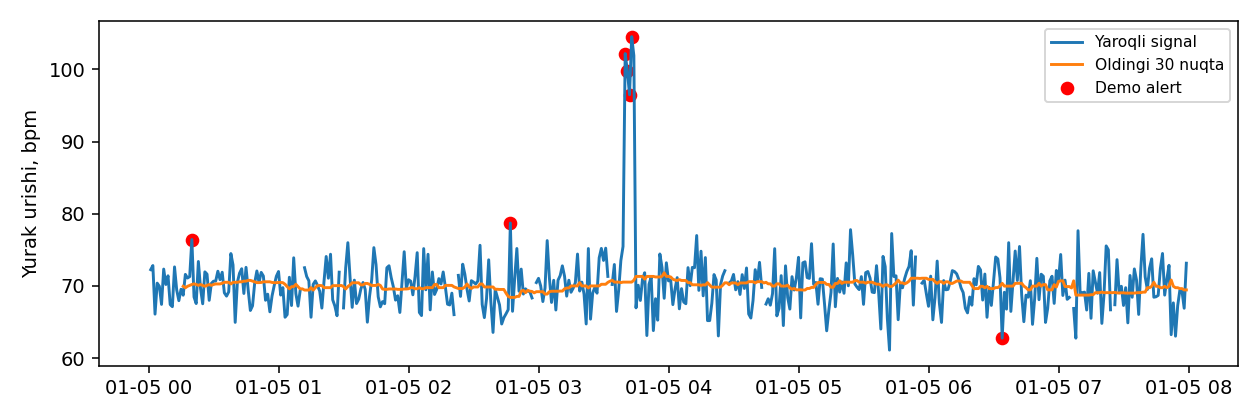

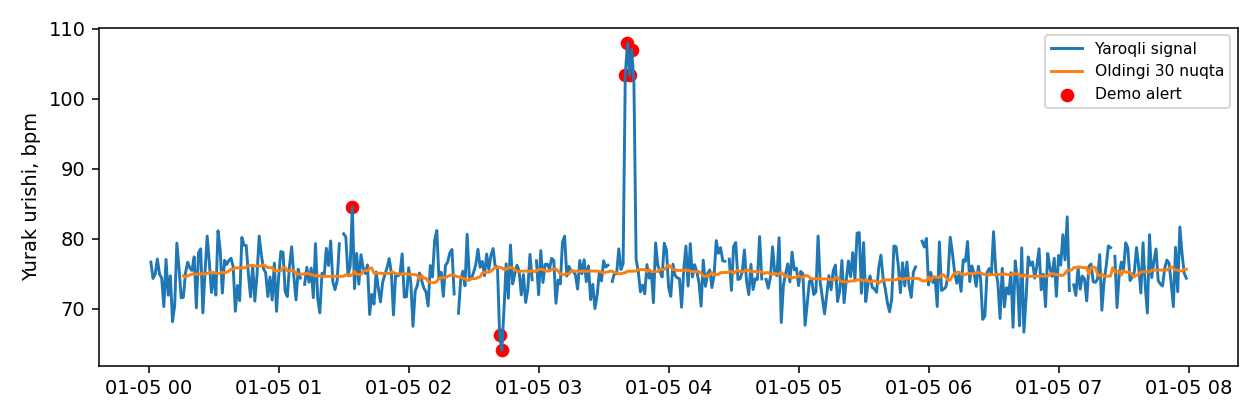

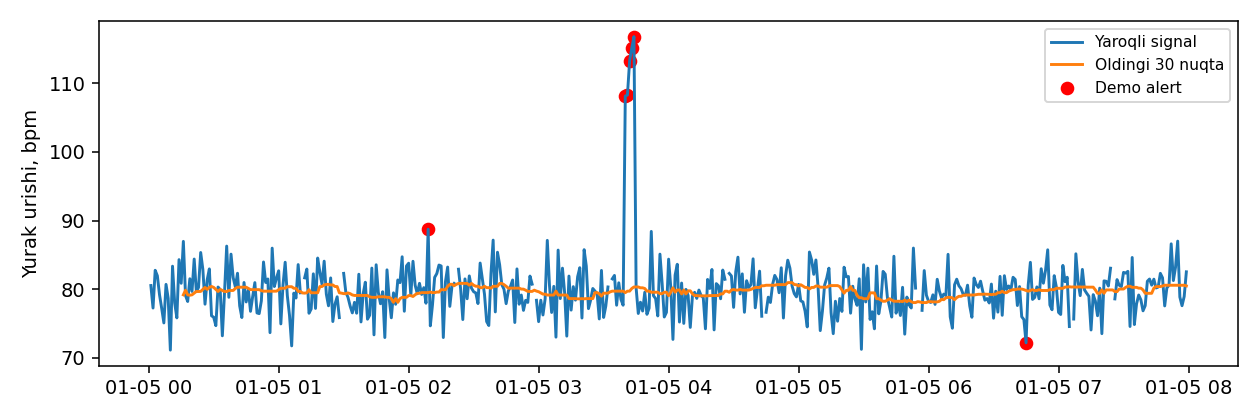

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
